# Análisis Exploratorio: S&P 500 (Cierre y Promedio) y VIX vs. Economía Mexicana

Este notebook evalúa la relación entre las condiciones financieras y bursátiles de Estados Unidos y la economía mexicana, a partir del dataset integrado `data/processed/proyecto_integrado_mensual.parquet`.

El análisis se divide en tres secciones y una síntesis comparativa:
1. **Parte 1:** S&P 500 al Cierre Mensual (`SP500_CIERRE`).
2. **Parte 2:** S&P 500 al Promedio Mensual (`SP500_PROMEDIO`).
3. **Parte 3:** Índice de Volatilidad CBOE (`VIX_CIERRE` - Aversión al riesgo e incertidumbre global).
4. **Comparativa Integral:** Tabla resumen de correlaciones de Pearson entre las tres métricas internacionales y las variables macroeconómicas de México.

## Justificación Técnica del Uso de Rendimientos y Métricas Globales

1. **Rendimientos Interanuales a 12 meses ($\Delta_{12} X_t$):** En niveles brutos, las series macroeconómicas y bursátiles presentan tendencias temporales de largo plazo que pueden generar correlaciones espurias (alta correlación simplemente porque ambas series suben en el tiempo). El rendimiento a 12 meses estabiliza la serie y permite comparar todas las variables en la misma escala: **tasa de variación porcentual anual (%)**.
2. **Cierre vs. Promedio Mensual del S&P 500:** El cierre puntual captura la cotización del último día hábil, expuesto a volatilidad intradiaria. El promedio mensual de días hábiles refleja de forma más representativa el apetito por riesgo a lo largo de todo el mes, haciéndolo comparable con variables de flujo mensual acumulado como el IGAE o la recaudación fiscal.
3. **Inclusión del VIX (`VIX_CIERRE`):** Mientras que el S&P 500 mide el desempeño del mercado accionario, el VIX cuantifica la volatilidad esperada y el estrés financiero global. En periodos de alta incertidumbre internacional, el VIX suele dispararse y sincronizarse de manera inmediata con presiones en la economía mexicana.

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if Path.cwd().name == "notebooks" and (Path.cwd().parent / "pipeline.py").exists():
    os.chdir("..")

DATA_PATH = Path("data/processed/proyecto_integrado_mensual.parquet")
print("Ruta del archivo:", DATA_PATH)

df = pd.read_parquet(DATA_PATH)
df["PERIODO"] = pd.to_datetime(df["PERIODO"])
df = df.sort_values("PERIODO").reset_index(drop=True)

print(f"Dimensiones en bruto: {df.shape} (187 meses x {df.shape[1]} columnas)")
display(df.head(5))


Ruta del archivo: data\processed\proyecto_integrado_mensual.parquet
Dimensiones en bruto: (283, 12) (187 meses x 12 columnas)


,PERIODO,INGRESOS_REALES,GASTOS_REALES,Total,INPC,Actividades primarias,Actividades secundarias,Actividades terciarias,TC_CIERRE,SP500_CIERRE,SP500_PROMEDIO,VIX_CIERRE
0,2003-01-01,3.133723e+08,2.839016e+08,72.570800,53.525441,78.772727,80.862039,67.515524,10.9069,855.700012,895.836190,31.170000
1,2003-02-01,2.265180e+08,2.588788e+08,70.941246,53.674122,67.587174,80.452379,65.725404,11.0324,841.150024,837.618951,29.629999
2,2003-03-01,2.739598e+08,2.548191e+08,73.522296,54.012930,66.484656,82.966723,68.549566,10.7889,848.179993,846.621425,29.150000
3,2003-04-01,2.998653e+08,2.390545e+08,73.556142,54.105144,67.365467,81.709850,69.269406,10.3000,916.919983,890.025713,21.209999
4,2003-05-01,2.297207e+08,2.420845e+08,74.759866,53.930560,75.355371,81.980533,70.625063,10.3377,963.590027,935.962853,19.469999


In [2]:
# Cálculo de rendimientos interanuales a 12 meses para todas las variables numéricas
cols_calc = [
    "SP500_CIERRE", "SP500_PROMEDIO", "VIX_CIERRE", "TC_CIERRE", "INPC",
    "INGRESOS_REALES", "GASTOS_REALES",
    "Total", "Actividades primarias", "Actividades secundarias", "Actividades terciarias"
]

# Verificamos columnas presentes en df
cols_disponibles = [c for c in cols_calc if c in df.columns]

df_ret = pd.DataFrame({"PERIODO": df["PERIODO"]})
for col in cols_disponibles:
    df_ret[f"RET_{col}"] = df[col].pct_change(12) * 100.0

df_ret = df_ret.dropna().reset_index(drop=True)
print(f"Dimensiones con rendimientos (12M): {df_ret.shape} (175 meses evaluables)")
display(df_ret.head(5))


Dimensiones con rendimientos (12M): (271, 12) (175 meses evaluables)


,PERIODO,RET_SP500_CIERRE,RET_SP500_PROMEDIO,RET_VIX_CIERRE,RET_TC_CIERRE,RET_INPC,RET_INGRESOS_REALES,RET_GASTOS_REALES,RET_Total,RET_Actividades primarias,RET_Actividades secundarias,RET_Actividades terciarias
0,2004-01-01,32.187681,26.420155,-46.647420,1.049794,4.201510,9.208808,2.113869,1.432230,11.479506,3.087925,-0.347274
1,2004-02-01,36.116021,36.500771,-50.894362,0.255611,4.534443,-0.449081,-12.717865,2.277975,11.189415,2.079867,1.905185
2,2004-03-01,32.779595,32.760430,-42.572899,3.576824,4.230729,6.142037,11.795497,5.765116,2.610897,6.458176,5.459066
3,2004-04-01,20.762997,27.308521,-18.953318,10.769903,4.210113,2.813907,6.705184,3.342803,4.232569,4.831603,2.297014
4,2004-05-01,16.302579,17.823212,-20.390341,10.418178,4.285220,-0.970375,-2.508355,2.989880,3.247664,3.018683,2.955564


# PARTE 1: Análisis con S&P 500 al Cierre Mensual (`RET_SP500_CIERRE`)
Evaluamos la tasa de variación anual del índice accionario tomada al cierre del último día hábil de cada mes.

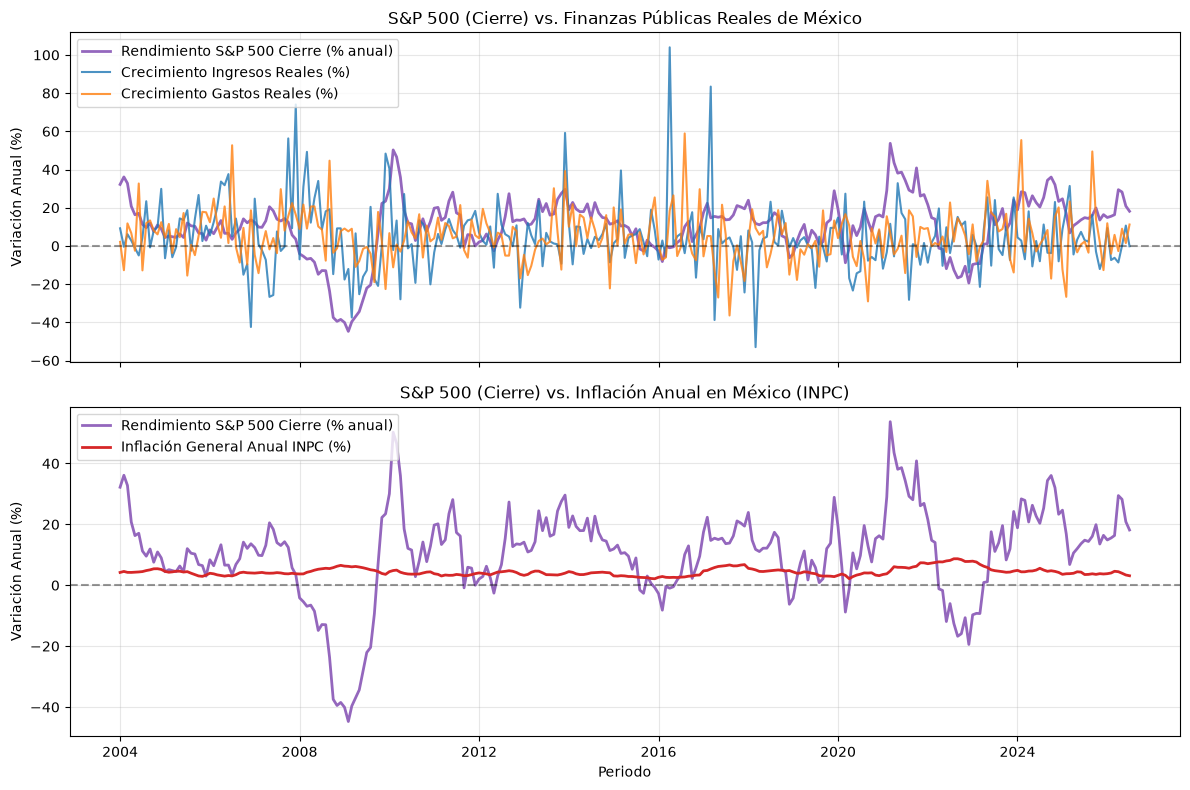

In [3]:
# 1.1 Series de tiempo: S&P 500 Cierre vs. Finanzas Públicas Reales e Inflación
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Panel 1: S&P 500 Cierre vs Finanzas Públicas
ax1.plot(df_ret["PERIODO"], df_ret["RET_SP500_CIERRE"], label="Rendimiento S&P 500 Cierre (% anual)", color="tab:purple", linewidth=2)
ax1.plot(df_ret["PERIODO"], df_ret["RET_INGRESOS_REALES"], label="Crecimiento Ingresos Reales (%)", color="tab:blue", alpha=0.8)
ax1.plot(df_ret["PERIODO"], df_ret["RET_GASTOS_REALES"], label="Crecimiento Gastos Reales (%)", color="tab:orange", alpha=0.8)
ax1.axhline(0, color="black", linestyle="--", alpha=0.4)
ax1.set_ylabel("Variación Anual (%)")
ax1.set_title("S&P 500 (Cierre) vs. Finanzas Públicas Reales de México")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

# Panel 2: S&P 500 Cierre vs Inflación (INPC)
ax2.plot(df_ret["PERIODO"], df_ret["RET_SP500_CIERRE"], label="Rendimiento S&P 500 Cierre (% anual)", color="tab:purple", linewidth=2)
if "RET_INPC" in df_ret.columns:
    ax2.plot(df_ret["PERIODO"], df_ret["RET_INPC"], label="Inflación General Anual INPC (%)", color="tab:red", linewidth=2)
ax2.axhline(0, color="black", linestyle="--", alpha=0.4)
ax2.set_xlabel("Periodo")
ax2.set_ylabel("Variación Anual (%)")
ax2.set_title("S&P 500 (Cierre) vs. Inflación Anual en México (INPC)")
ax2.legend(loc="upper left")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


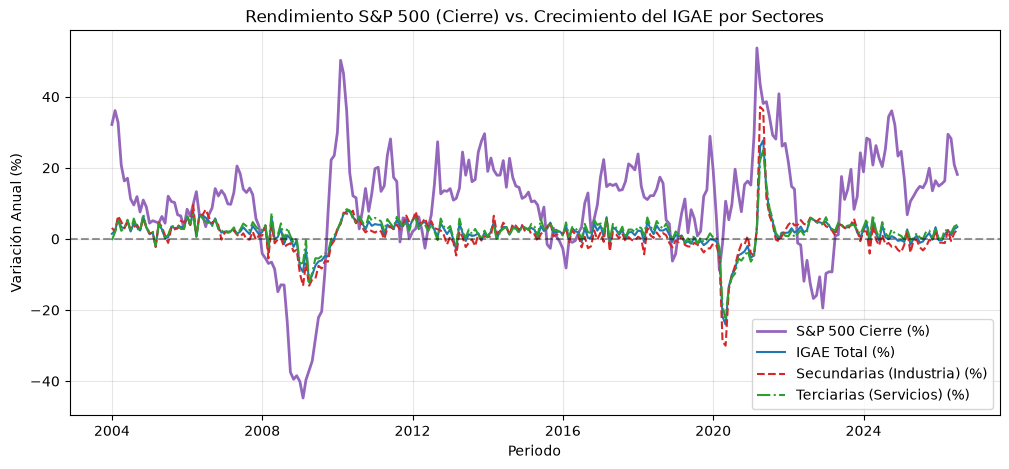

In [4]:
# 1.2 Serie de tiempo: S&P 500 Cierre vs. Sectores del IGAE
plt.figure(figsize=(12, 5))
plt.plot(df_ret["PERIODO"], df_ret["RET_SP500_CIERRE"], label="S&P 500 Cierre (%)", color="tab:purple", linewidth=2)
plt.plot(df_ret["PERIODO"], df_ret["RET_Total"], label="IGAE Total (%)", color="tab:blue")
plt.plot(df_ret["PERIODO"], df_ret["RET_Actividades secundarias"], label="Secundarias (Industria) (%)", color="tab:red", linestyle="--")
plt.plot(df_ret["PERIODO"], df_ret["RET_Actividades terciarias"], label="Terciarias (Servicios) (%)", color="tab:green", linestyle="-.")
plt.axhline(0, color="black", linestyle="--", alpha=0.4)

plt.title("Rendimiento S&P 500 (Cierre) vs. Crecimiento del IGAE por Sectores")
plt.xlabel("Periodo")
plt.ylabel("Variación Anual (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


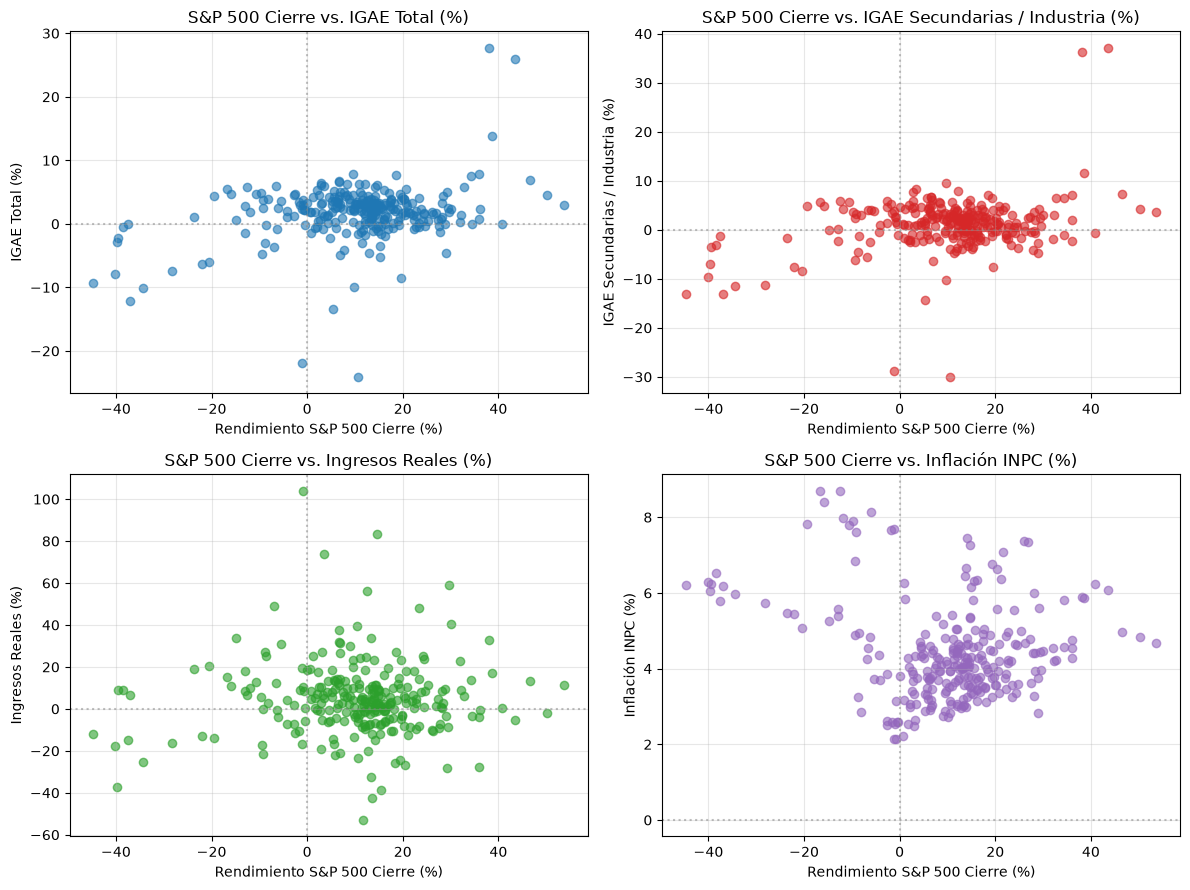

In [5]:
# 1.3 Diagramas de dispersión (Scatter Plots) - S&P 500 Cierre
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

pairs_cierre = [
    ("RET_Total", "IGAE Total (%)", "tab:blue", axes[0, 0]),
    ("RET_Actividades secundarias", "IGAE Secundarias / Industria (%)", "tab:red", axes[0, 1]),
    ("RET_INGRESOS_REALES", "Ingresos Reales (%)", "tab:green", axes[1, 0]),
    ("RET_INPC", "Inflación INPC (%)", "tab:purple", axes[1, 1])
]

for col_target, label_target, color, ax in pairs_cierre:
    if col_target in df_ret.columns:
        ax.scatter(df_ret["RET_SP500_CIERRE"], df_ret[col_target], alpha=0.6, color=color)
        ax.set_title(f"S&P 500 Cierre vs. {label_target}")
        ax.set_xlabel("Rendimiento S&P 500 Cierre (%)")
        ax.set_ylabel(label_target)
        ax.axvline(0, color="gray", linestyle=":", alpha=0.5)
        ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Correlación de Pearson frente al S&P 500 al Cierre:


,RET_SP500_CIERRE
RET_SP500_CIERRE,1.0000
RET_INPC,-0.1980
RET_INGRESOS_REALES,0.0289
RET_GASTOS_REALES,-0.0416
RET_Total,0.3207
RET_Actividades primarias,0.0856
RET_Actividades secundarias,0.3119
RET_Actividades terciarias,0.3059


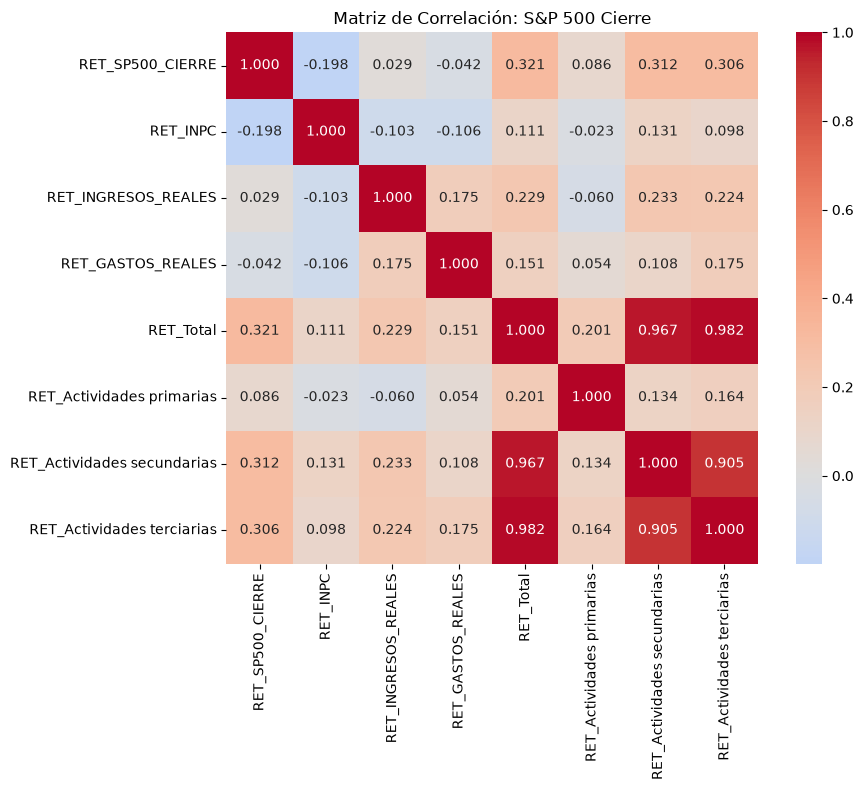

In [6]:
# 1.4 Matriz de correlación de Pearson - S&P 500 Cierre
cols_corr_cierre = [
    "RET_SP500_CIERRE", "RET_INPC", "RET_INGRESOS_REALES", "RET_GASTOS_REALES",
    "RET_Total", "RET_Actividades primarias", "RET_Actividades secundarias", "RET_Actividades terciarias"
]
cols_corr_cierre = [c for c in cols_corr_cierre if c in df_ret.columns]
corr_cierre = df_ret[cols_corr_cierre].corr(method="pearson")

print("Correlación de Pearson frente al S&P 500 al Cierre:")
display(corr_cierre[["RET_SP500_CIERRE"]].round(4))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_cierre, annot=True, cmap="coolwarm", center=0, fmt=".3f", square=True)
plt.title("Matriz de Correlación: S&P 500 Cierre")
plt.tight_layout()
plt.show()


# PARTE 2: Análisis con S&P 500 al Promedio Mensual (`RET_SP500_PROMEDIO`)
Evaluamos la tasa de variación anual del promedio mensual de cotizaciones diarias para mitigar la volatilidad intrames.

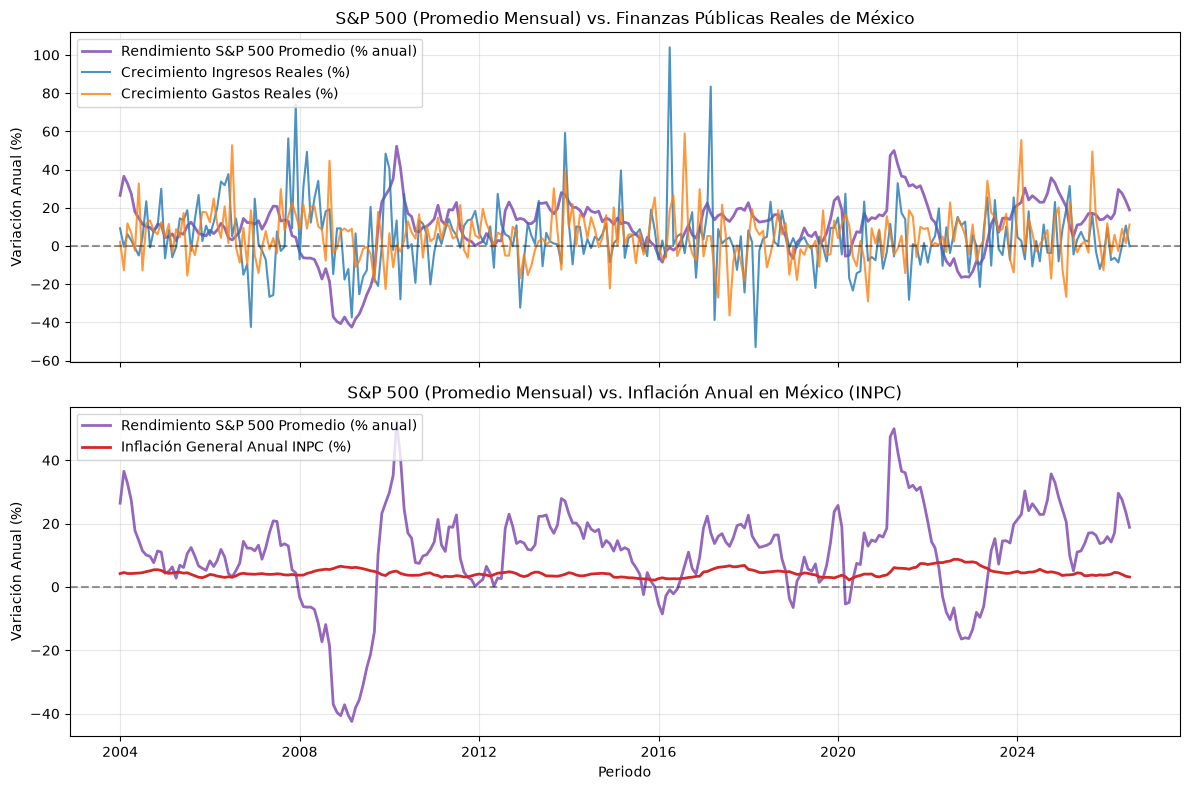

In [7]:
# 2.1 Series de tiempo: S&P 500 Promedio vs. Finanzas Públicas Reales e Inflación
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Panel 1: S&P 500 Promedio vs Finanzas Públicas
ax1.plot(df_ret["PERIODO"], df_ret["RET_SP500_PROMEDIO"], label="Rendimiento S&P 500 Promedio (% anual)", color="tab:purple", linewidth=2)
ax1.plot(df_ret["PERIODO"], df_ret["RET_INGRESOS_REALES"], label="Crecimiento Ingresos Reales (%)", color="tab:blue", alpha=0.8)
ax1.plot(df_ret["PERIODO"], df_ret["RET_GASTOS_REALES"], label="Crecimiento Gastos Reales (%)", color="tab:orange", alpha=0.8)
ax1.axhline(0, color="black", linestyle="--", alpha=0.4)
ax1.set_ylabel("Variación Anual (%)")
ax1.set_title("S&P 500 (Promedio Mensual) vs. Finanzas Públicas Reales de México")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

# Panel 2: S&P 500 Promedio vs Inflación (INPC)
ax2.plot(df_ret["PERIODO"], df_ret["RET_SP500_PROMEDIO"], label="Rendimiento S&P 500 Promedio (% anual)", color="tab:purple", linewidth=2)
if "RET_INPC" in df_ret.columns:
    ax2.plot(df_ret["PERIODO"], df_ret["RET_INPC"], label="Inflación General Anual INPC (%)", color="tab:red", linewidth=2)
ax2.axhline(0, color="black", linestyle="--", alpha=0.4)
ax2.set_xlabel("Periodo")
ax2.set_ylabel("Variación Anual (%)")
ax2.set_title("S&P 500 (Promedio Mensual) vs. Inflación Anual en México (INPC)")
ax2.legend(loc="upper left")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


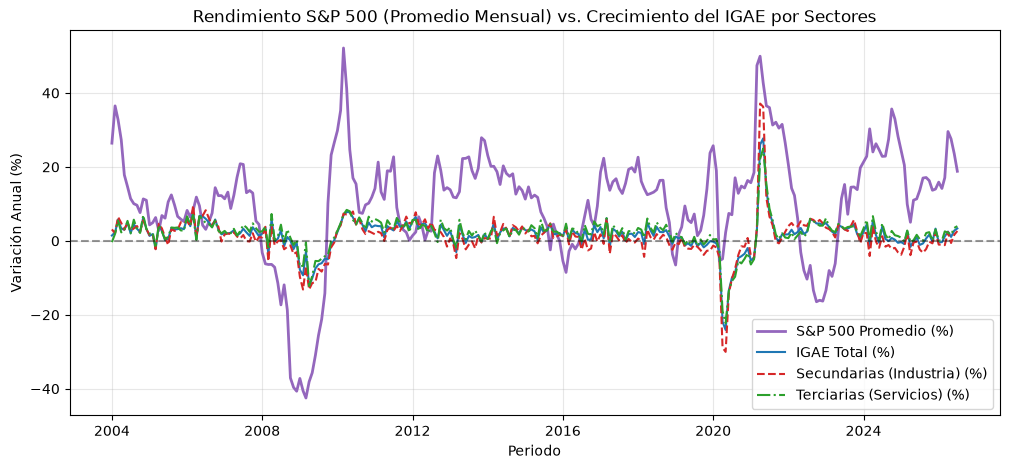

In [8]:
# 2.2 Serie de tiempo: S&P 500 Promedio vs. Sectores del IGAE
plt.figure(figsize=(12, 5))
plt.plot(df_ret["PERIODO"], df_ret["RET_SP500_PROMEDIO"], label="S&P 500 Promedio (%)", color="tab:purple", linewidth=2)
plt.plot(df_ret["PERIODO"], df_ret["RET_Total"], label="IGAE Total (%)", color="tab:blue")
plt.plot(df_ret["PERIODO"], df_ret["RET_Actividades secundarias"], label="Secundarias (Industria) (%)", color="tab:red", linestyle="--")
plt.plot(df_ret["PERIODO"], df_ret["RET_Actividades terciarias"], label="Terciarias (Servicios) (%)", color="tab:green", linestyle="-.")
plt.axhline(0, color="black", linestyle="--", alpha=0.4)

plt.title("Rendimiento S&P 500 (Promedio Mensual) vs. Crecimiento del IGAE por Sectores")
plt.xlabel("Periodo")
plt.ylabel("Variación Anual (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


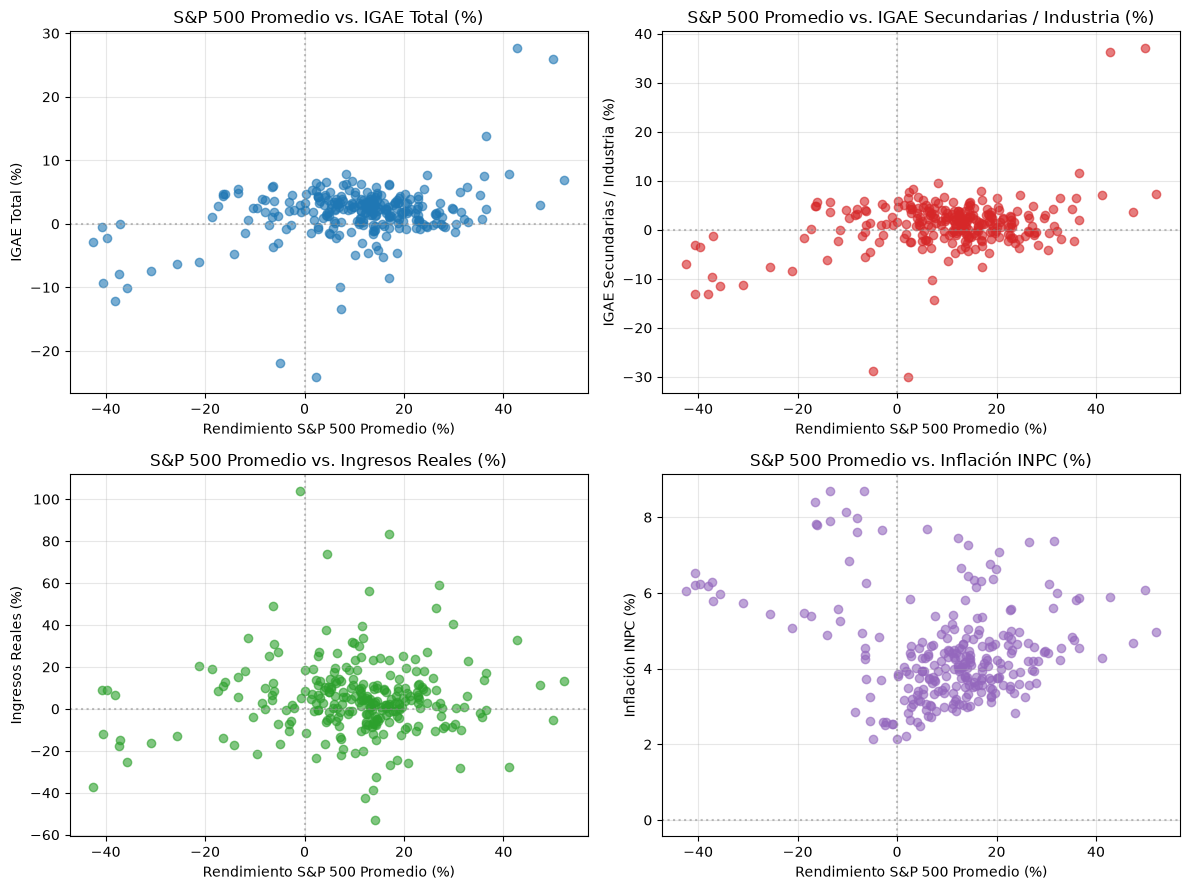

In [9]:
# 2.3 Diagramas de dispersión (Scatter Plots) - S&P 500 Promedio
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

pairs_prom = [
    ("RET_Total", "IGAE Total (%)", "tab:blue", axes[0, 0]),
    ("RET_Actividades secundarias", "IGAE Secundarias / Industria (%)", "tab:red", axes[0, 1]),
    ("RET_INGRESOS_REALES", "Ingresos Reales (%)", "tab:green", axes[1, 0]),
    ("RET_INPC", "Inflación INPC (%)", "tab:purple", axes[1, 1])
]

for col_target, label_target, color, ax in pairs_prom:
    if col_target in df_ret.columns:
        ax.scatter(df_ret["RET_SP500_PROMEDIO"], df_ret[col_target], alpha=0.6, color=color)
        ax.set_title(f"S&P 500 Promedio vs. {label_target}")
        ax.set_xlabel("Rendimiento S&P 500 Promedio (%)")
        ax.set_ylabel(label_target)
        ax.axvline(0, color="gray", linestyle=":", alpha=0.5)
        ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Correlación de Pearson frente al S&P 500 al Promedio Mensual:


,RET_SP500_PROMEDIO
RET_SP500_PROMEDIO,1.0000
RET_INPC,-0.1885
RET_INGRESOS_REALES,0.0487
RET_GASTOS_REALES,-0.0379
RET_Total,0.3617
RET_Actividades primarias,0.0780
RET_Actividades secundarias,0.3538
RET_Actividades terciarias,0.3462


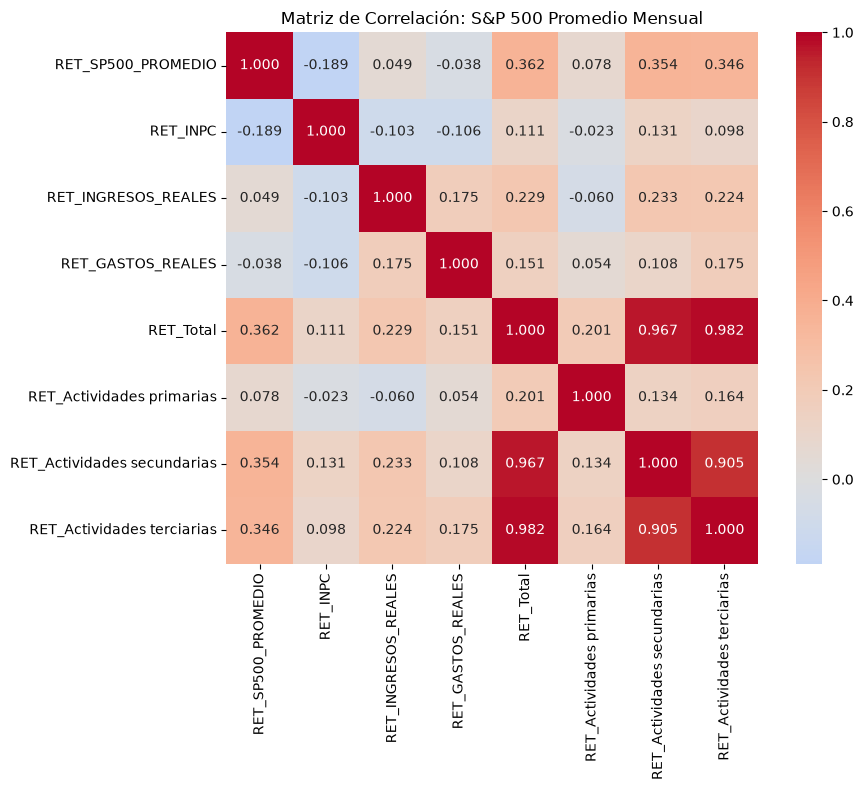

In [10]:
# 2.4 Matriz de correlación de Pearson - S&P 500 Promedio
cols_corr_prom = [
    "RET_SP500_PROMEDIO", "RET_INPC", "RET_INGRESOS_REALES", "RET_GASTOS_REALES",
    "RET_Total", "RET_Actividades primarias", "RET_Actividades secundarias", "RET_Actividades terciarias"
]
cols_corr_prom = [c for c in cols_corr_prom if c in df_ret.columns]
corr_prom = df_ret[cols_corr_prom].corr(method="pearson")

print("Correlación de Pearson frente al S&P 500 al Promedio Mensual:")
display(corr_prom[["RET_SP500_PROMEDIO"]].round(4))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_prom, annot=True, cmap="coolwarm", center=0, fmt=".3f", square=True)
plt.title("Matriz de Correlación: S&P 500 Promedio Mensual")
plt.tight_layout()
plt.show()


# PARTE 3: Análisis de Volatilidad y Aversión al Riesgo Global (`VIX_CIERRE`)
Evaluamos el comportamiento del **Índice de Volatilidad CBOE (VIX)** al cierre mensual frente al Tipo de Cambio USD/MXN, la Inflación y la Actividad Económica Mexicana.

*Nota:* Para el VIX se analiza tanto su nivel en puntos (niveles superiores a 20-25 puntos denotan episodios de estrés y pánico financiero internacional) como su tasa de variación interanual (`RET_VIX_CIERRE`).

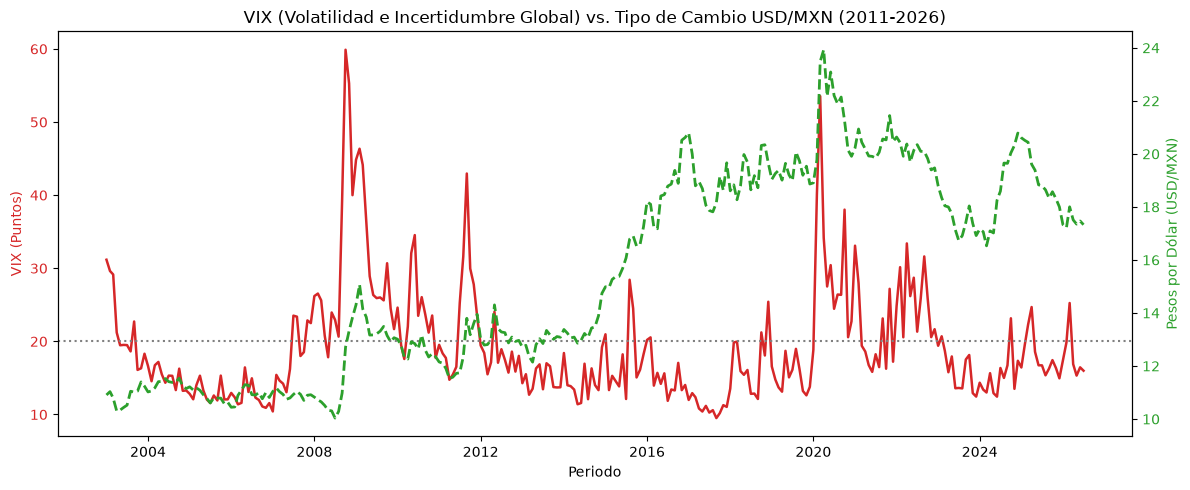

In [11]:
# 3.1 Serie de tiempo: VIX vs. Tipo de Cambio USD/MXN (Canal de Transmisión de Incertidumbre)
fig, ax1 = plt.subplots(figsize=(12, 5))

# Eje 1: Nivel del VIX
color_vix = "tab:red"
ax1.plot(df["PERIODO"], df["VIX_CIERRE"], label="VIX Cierre (Puntos de Volatilidad)", color=color_vix, linewidth=1.8)
ax1.axhline(20, color="gray", linestyle=":", label="Umbral de alerta VIX (20 pts)")
ax1.set_xlabel("Periodo")
ax1.set_ylabel("VIX (Puntos)", color=color_vix)
ax1.tick_params(axis="y", labelcolor=color_vix)

# Eje 2: Tipo de Cambio FIX
ax2 = ax1.twinx()
color_tc = "tab:green"
ax2.plot(df["PERIODO"], df["TC_CIERRE"], label="Tipo de Cambio FIX (USD/MXN)", color=color_tc, linestyle="--", linewidth=2)
ax2.set_ylabel("Pesos por Dólar (USD/MXN)", color=color_tc)
ax2.tick_params(axis="y", labelcolor=color_tc)

plt.title("VIX (Volatilidad e Incertidumbre Global) vs. Tipo de Cambio USD/MXN (2011-2026)")
fig.tight_layout()
plt.show()


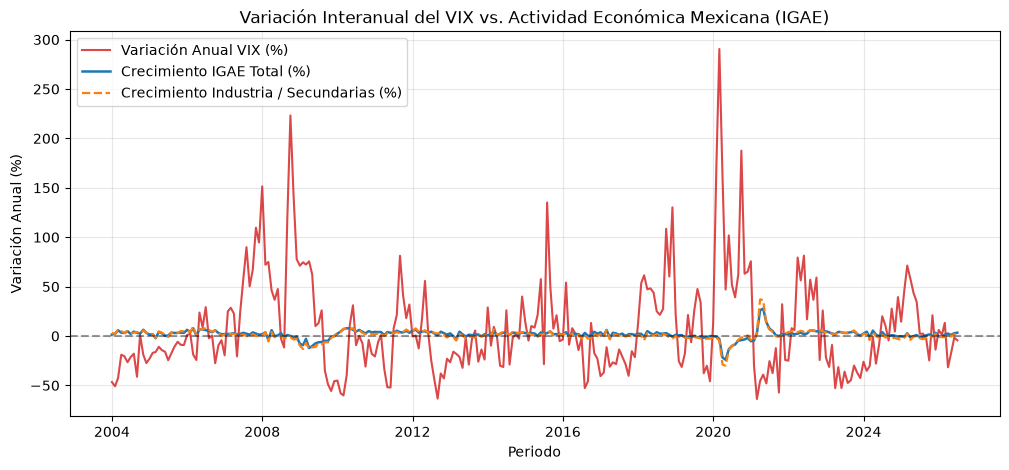

In [12]:
# 3.2 Rendimiento de VIX vs. Crecimiento del IGAE y Finanzas Públicas
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_ret["PERIODO"], df_ret["RET_VIX_CIERRE"], label="Variación Anual VIX (%)", color="tab:red", linewidth=1.5, alpha=0.85)
ax.plot(df_ret["PERIODO"], df_ret["RET_Total"], label="Crecimiento IGAE Total (%)", color="tab:blue", linewidth=1.8)
ax.plot(df_ret["PERIODO"], df_ret["RET_Actividades secundarias"], label="Crecimiento Industria / Secundarias (%)", color="tab:orange", linestyle="--", linewidth=1.6)
ax.axhline(0, color="black", linestyle="--", alpha=0.4)

ax.set_title("Variación Interanual del VIX vs. Actividad Económica Mexicana (IGAE)")
ax.set_xlabel("Periodo")
ax.set_ylabel("Variación Anual (%)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()


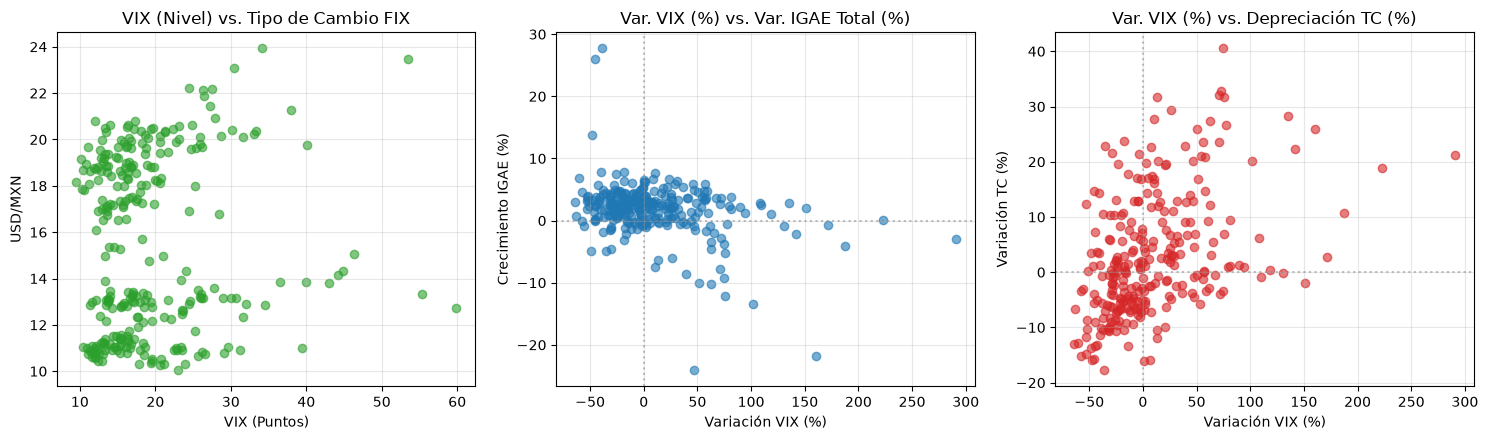

In [13]:
# 3.3 Diagramas de dispersión - VIX
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# VIX vs TC_CIERRE (en niveles: a mayor estrés global, ¿mayor tipo de cambio?)
axes[0].scatter(df["VIX_CIERRE"], df["TC_CIERRE"], alpha=0.6, color="tab:green")
axes[0].set_title("VIX (Nivel) vs. Tipo de Cambio FIX")
axes[0].set_xlabel("VIX (Puntos)")
axes[0].set_ylabel("USD/MXN")
axes[0].grid(True, alpha=0.3)

# RET_VIX vs RET_Total (en variaciones: picos de volatilidad vs contracción IGAE)
axes[1].scatter(df_ret["RET_VIX_CIERRE"], df_ret["RET_Total"], alpha=0.6, color="tab:blue")
axes[1].set_title("Var. VIX (%) vs. Var. IGAE Total (%)")
axes[1].set_xlabel("Variación VIX (%)")
axes[1].set_ylabel("Crecimiento IGAE (%)")
axes[1].axvline(0, color="gray", linestyle=":", alpha=0.5)
axes[1].axhline(0, color="gray", linestyle=":", alpha=0.5)
axes[1].grid(True, alpha=0.3)

# RET_VIX vs RET_TC_CIERRE (en variaciones: ¿se deprecia el peso al subir el VIX?)
axes[2].scatter(df_ret["RET_VIX_CIERRE"], df_ret["RET_TC_CIERRE"], alpha=0.6, color="tab:red")
axes[2].set_title("Var. VIX (%) vs. Depreciación TC (%)")
axes[2].set_xlabel("Variación VIX (%)")
axes[2].set_ylabel("Variación TC (%)")
axes[2].axvline(0, color="gray", linestyle=":", alpha=0.5)
axes[2].axhline(0, color="gray", linestyle=":", alpha=0.5)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Correlación de Pearson frente a la Variación Anual del VIX:


,RET_VIX_CIERRE
RET_VIX_CIERRE,1.0000
RET_TC_CIERRE,0.4400
RET_INPC,-0.0110
RET_INGRESOS_REALES,0.0064
RET_Total,-0.3280
RET_Actividades secundarias,-0.3108
RET_Actividades terciarias,-0.3268


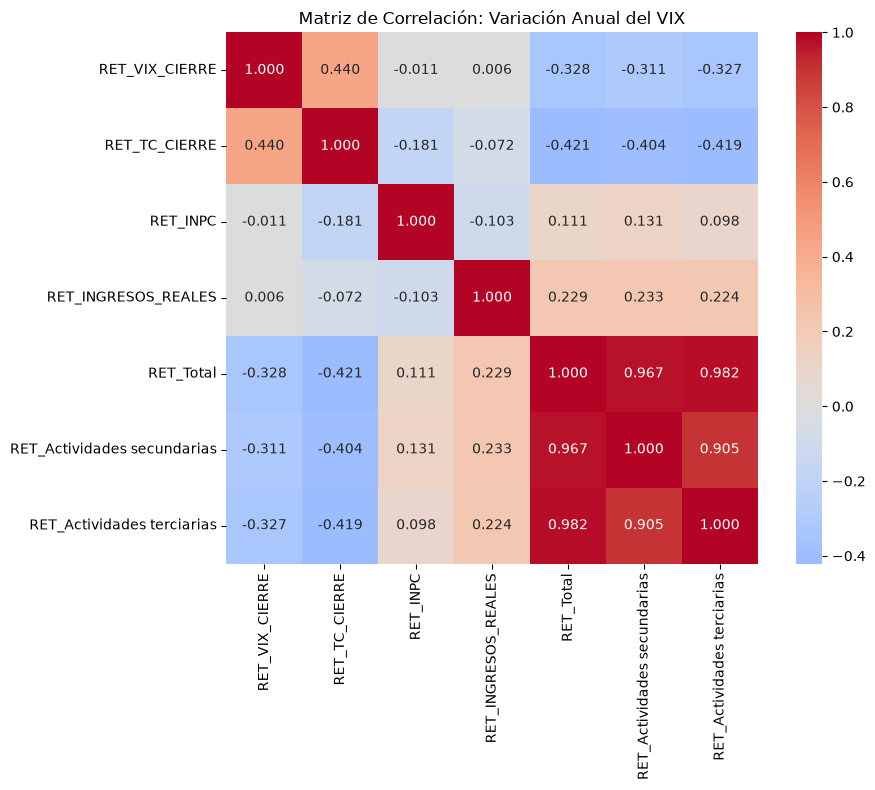

In [14]:
# 3.4 Matriz de correlación de Pearson - VIX
cols_corr_vix = [
    "RET_VIX_CIERRE", "RET_TC_CIERRE", "RET_INPC", "RET_INGRESOS_REALES",
    "RET_Total", "RET_Actividades secundarias", "RET_Actividades terciarias"
]
cols_corr_vix = [c for c in cols_corr_vix if c in df_ret.columns]
corr_vix = df_ret[cols_corr_vix].corr(method="pearson")

print("Correlación de Pearson frente a la Variación Anual del VIX:")
display(corr_vix[["RET_VIX_CIERRE"]].round(4))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_vix, annot=True, cmap="coolwarm", center=0, fmt=".3f", square=True)
plt.title("Matriz de Correlación: Variación Anual del VIX")
plt.tight_layout()
plt.show()


# COMPARATIVA INTEGRAL: S&P 500 Cierre vs. S&P 500 Promedio vs. VIX Cierre
Comparamos en una sola tabla la correlación de Pearson de las tres métricas financieras globales frente a cada una de las variables económicas mexicanas.

=== COMPARATIVA DE CORRELACIÓN DE PEARSON (RENDIMIENTOS 12M) ===


,S&P 500 Cierre,S&P 500 Promedio,VIX Cierre (Volatilidad)
RET_INPC,-0.1980,-0.1885,-0.0110
RET_INGRESOS_REALES,0.0289,0.0487,0.0064
RET_GASTOS_REALES,-0.0416,-0.0379,0.0620
RET_Total,0.3207,0.3617,-0.3280
RET_Actividades primarias,0.0856,0.0780,-0.0086
RET_Actividades secundarias,0.3119,0.3538,-0.3108
RET_Actividades terciarias,0.3059,0.3462,-0.3268
RET_TC_CIERRE,-0.4813,-0.4695,0.4400


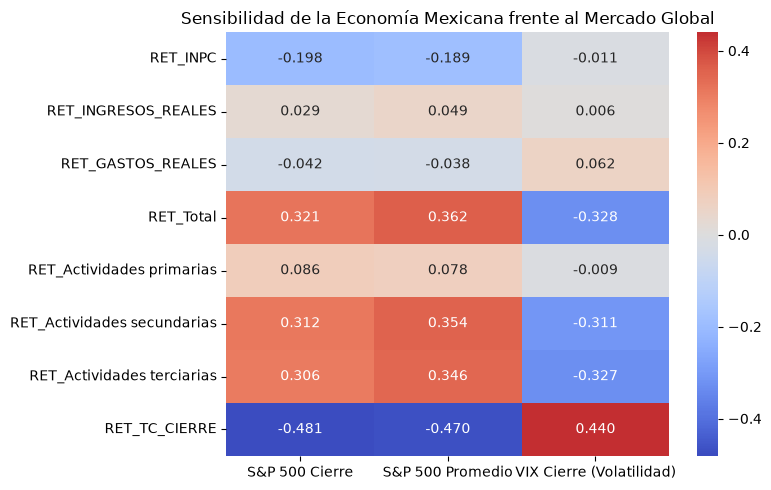

In [15]:
# Tabla comparativa de correlación en rendimientos (Pearson)
vars_mexico = [
    "RET_INPC",
    "RET_INGRESOS_REALES",
    "RET_GASTOS_REALES",
    "RET_Total",
    "RET_Actividades primarias",
    "RET_Actividades secundarias",
    "RET_Actividades terciarias",
    "RET_TC_CIERRE"
]
vars_mexico = [v for v in vars_mexico if v in df_ret.columns]

matriz_global = df_ret.corr(method="pearson")

resumen_comp = pd.DataFrame(index=vars_mexico)
if "RET_SP500_CIERRE" in matriz_global.columns:
    resumen_comp["S&P 500 Cierre"] = matriz_global.loc[vars_mexico, "RET_SP500_CIERRE"]
if "RET_SP500_PROMEDIO" in matriz_global.columns:
    resumen_comp["S&P 500 Promedio"] = matriz_global.loc[vars_mexico, "RET_SP500_PROMEDIO"]
if "RET_VIX_CIERRE" in matriz_global.columns:
    resumen_comp["VIX Cierre (Volatilidad)"] = matriz_global.loc[vars_mexico, "RET_VIX_CIERRE"]

print("=== COMPARATIVA DE CORRELACIÓN DE PEARSON (RENDIMIENTOS 12M) ===")
display(resumen_comp.round(4))

# Visualización en mapa de calor comparativo
plt.figure(figsize=(8, 5))
sns.heatmap(resumen_comp, annot=True, cmap="coolwarm", center=0, fmt=".3f", cbar=True)
plt.title("Sensibilidad de la Economía Mexicana frente al Mercado Global")
plt.tight_layout()
plt.show()
